# Лабораторна робота №3. Дискретне перетворення Фур'є

Варіант 23.

## Вихідні дані

Десять вибірок f(nTₐ) з таблиці варіанту, n = 0…9. Для варіантів 15–30 період дискретизації Tₐ = 0,4 с, тому fₐ = 1/Tₐ = 2,5 Гц, час спостереження NTₐ = 4 с, а розрізнення за частотою Δf = 1/(NTₐ) = 0,25 Гц (формула (44)). Рядок nTₐ у таблиці надрукований для Tₐ = 0,1 с, тому моменти вибірок перераховано як n·0,4 с.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

variant_number = 23
sample_numbers = np.arange(10)
sample_values = np.array([0.0, -2.0, -5.0, -3.0, 0.3, 2.0, 1.2, -0.6, -1.2, 0.0])
sample_count = len(sample_values)

# Variants 15-30 use Ta = 0.4 s (fa = 2.5 Hz, NTa = 4 s). The table row nTa = 0...0.9 is printed
# for Ta = 0.1 s, so the sample times are recomputed from the sampling period of our variant.
sampling_period = 0.4
sampling_frequency = 1 / sampling_period
observation_time = sample_count * sampling_period
frequency_resolution = 1 / observation_time  # formula (44) of the guide
sample_times = sample_numbers * sampling_period


def clean(value):
    """Round away float noise, so a tiny negative number prints as 0.000000, not -0.000000."""
    return np.round(value, 10) + 0.0


print(f"Variant {variant_number}, N = {sample_count}")
print("n:      ", sample_numbers)
print("nTa, s: ", sample_times)
print("f(nTa): ", sample_values)
print(f"Ta = {sampling_period} s, fa = {sampling_frequency} Hz, NTa = {observation_time} s,"
      f" delta f = {frequency_resolution} Hz")

Variant 23, N = 10
n:       [0 1 2 3 4 5 6 7 8 9]
nTa, s:  [0.  0.4 0.8 1.2 1.6 2.  2.4 2.8 3.2 3.6]
f(nTa):  [ 0.  -2.  -5.  -3.   0.3  2.   1.2 -0.6 -1.2  0. ]
Ta = 0.4 s, fa = 2.5 Hz, NTa = 4.0 s, delta f = 0.25 Hz


## Завдання 1. ДПФ вручну

Спектральні лінії беруться на частотах f_k = k/(NTₐ) і ω_k = 2πk/(NTₐ), k = 0…N−1 (формули (37), (38)). Пряме ДПФ (39): F_d(jω_k) = Σ f(nTₐ)·e^(−jω_k·nTₐ). Як у прикладі методички, експонента розкладається на косинусну суму (дійсна частина) і синусну суму (уявна частина). Амплітуда |F_d| = √(Re² + Im²), а за формулою (36) її множимо на Tₐ: |F(jω_k)| = Tₐ·|F_d(jω_k)|. Коефіцієнти ряду Фур'є cₖ = F_d/N (47).

In [2]:
# Spectral lines are taken only at the N discrete frequencies of formulas (37) and (38).
harmonic_numbers = np.arange(sample_count)
line_frequencies = harmonic_numbers / observation_time  # f_k = k / (N * Ta), formula (38)
angular_frequencies = 2 * np.pi * line_frequencies  # w_k = 2 * pi * k / (N * Ta), formula (37)

# Formula (39): the sum of f(nTa) * exp(-j * w_k * nTa). As in the worked example of the guide,
# the exponent is split by Euler's formula into a cosine sum (real part) and a sine sum (imaginary part).
spectrum_real_parts = np.zeros(sample_count)
spectrum_imaginary_parts = np.zeros(sample_count)
for harmonic_index in range(sample_count):
    for sample_index in range(sample_count):
        phase = angular_frequencies[harmonic_index] * sample_times[sample_index]
        spectrum_real_parts[harmonic_index] += sample_values[sample_index] * np.cos(phase)
        spectrum_imaginary_parts[harmonic_index] -= sample_values[sample_index] * np.sin(phase)

hand_spectrum = spectrum_real_parts + 1j * spectrum_imaginary_parts
dft_magnitudes = np.sqrt(spectrum_real_parts ** 2 + spectrum_imaginary_parts ** 2)
# Formula (36): the DFT is multiplied by Ta, so it matches the ordinary Fourier transform in size and units.
amplitude_spectrum = sampling_period * dft_magnitudes
# Formula (47): the complex Fourier coefficients are the DFT divided by N.
fourier_coefficients = hand_spectrum / sample_count

print(f"{'k':>2} {'f_k, Hz':>8} {'w_k, rad/s':>11} {'Re F_d':>11} {'Im F_d':>11}"
      f" {'|F_d|':>10} {'|F(jw_k)|':>10} {'|c_k|':>9}")
for harmonic_index in range(sample_count):
    print(f"{harmonic_index:>2} {line_frequencies[harmonic_index]:8.2f}"
          f" {angular_frequencies[harmonic_index]:11.6f}"
          f" {clean(spectrum_real_parts[harmonic_index]):11.6f}"
          f" {clean(spectrum_imaginary_parts[harmonic_index]):11.6f}"
          f" {dft_magnitudes[harmonic_index]:10.6f} {amplitude_spectrum[harmonic_index]:10.6f}"
          f" {abs(fourier_coefficients[harmonic_index]):9.6f}")

maximum_index = np.argmax(amplitude_spectrum[: sample_count // 2 + 1])
print(f"maximum |F(jw_k)| = {amplitude_spectrum[maximum_index]:.6f} at k = {maximum_index}"
      f" (f = {line_frequencies[maximum_index]:.2f} Hz) and its mirror k = {sample_count - maximum_index}")

 k  f_k, Hz  w_k, rad/s      Re F_d      Im F_d      |F_d|  |F(jw_k)|     |c_k|
 0     0.00    0.000000   -8.300000    0.000000   8.300000   3.320000  0.830000
 1     0.25    1.570796   -5.635004    7.601128   9.462051   3.784820  0.946205
 2     0.50    3.141593    9.773858    1.869062   9.950964   3.980386  0.995096
 3     0.75    4.712389    1.185004   -0.886205   1.479727   0.591891  0.147973
 4     1.00    6.283185   -0.623858   -0.684915   0.926449   0.370580  0.092645
 5     1.25    7.853982   -1.100000    0.000000   1.100000   0.440000  0.110000
 6     1.50    9.424778   -0.623858    0.684915   0.926449   0.370580  0.092645
 7     1.75   10.995574    1.185004    0.886205   1.479727   0.591891  0.147973
 8     2.00   12.566371    9.773858   -1.869062   9.950964   3.980386  0.995096
 9     2.25   14.137167   -5.635004   -7.601128   9.462051   3.784820  0.946205
maximum |F(jw_k)| = 3.980386 at k = 2 (f = 0.50 Hz) and its mirror k = 8


## Перевірка через numpy.fft.fft

Те саме ДПФ функцією numpy.fft.fft, частоти ліній через numpy.fft.fftfreq. Порівнюється найбільша різниця між ручним і бібліотечним спектром.

In [3]:
library_spectrum = np.fft.fft(sample_values)
library_frequencies = np.fft.fftfreq(sample_count, d=sampling_period)
library_amplitude_spectrum = sampling_period * np.abs(library_spectrum)
spectrum_difference = np.max(np.abs(hand_spectrum - library_spectrum))
amplitude_difference = np.max(np.abs(amplitude_spectrum - library_amplitude_spectrum))

print(f"{'k':>2} {'Re fft':>11} {'Im fft':>11} {'Ta*|fft|':>10}")
for harmonic_index in range(sample_count):
    print(f"{harmonic_index:>2} {clean(library_spectrum[harmonic_index].real):11.6f}"
          f" {clean(library_spectrum[harmonic_index].imag):11.6f}"
          f" {library_amplitude_spectrum[harmonic_index]:10.6f}")
print("np.fft.fftfreq, Hz:", library_frequencies)
print(f"max |F_d hand - fft| = {spectrum_difference:.1e}")
print(f"max |F hand - F fft| = {amplitude_difference:.1e}")

 k      Re fft      Im fft   Ta*|fft|
 0   -8.300000    0.000000   3.320000
 1   -5.635004    7.601128   3.784820
 2    9.773858    1.869062   3.980386
 3    1.185004   -0.886205   0.591891
 4   -0.623858   -0.684915   0.370580
 5   -1.100000    0.000000   0.440000
 6   -0.623858    0.684915   0.370580
 7    1.185004    0.886205   0.591891
 8    9.773858   -1.869062   3.980386
 9   -5.635004   -7.601128   3.784820
np.fft.fftfreq, Hz: [ 0.    0.25  0.5   0.75  1.   -1.25 -1.   -0.75 -0.5  -0.25]
max |F_d hand - fft| = 1.3e-14
max |F hand - F fft| = 2.7e-15


## Перевірки: обернене ДПФ, Парсеваль, симетрія

Обернене ДПФ (41) має повернути вибірки. Тотожність Парсеваля: Σf² = Σ|F_d|²/N, де |F_d|² рахується як добуток ДПФ на спряжене до нього. Для дійсного сигналу лінія N−k спряжена до лінії k.

In [4]:
# Formula (41): the inverse DFT must give back the samples.
restored_values = np.zeros(sample_count, dtype=complex)
for sample_index in range(sample_count):
    for harmonic_index in range(sample_count):
        phase = angular_frequencies[harmonic_index] * sample_times[sample_index]
        restored_values[sample_index] += hand_spectrum[harmonic_index] * np.exp(1j * phase)
restored_values = restored_values / sample_count
hand_restore_error = np.max(np.abs(restored_values - sample_values))
library_restore_error = np.max(np.abs(np.fft.ifft(library_spectrum) - sample_values))

# Parseval: the signal energy equals the spectrum energy divided by N.
# The power spectrum is the DFT times its complex conjugate.
signal_energy = np.sum(sample_values ** 2)
power_spectrum = (hand_spectrum * np.conj(hand_spectrum)).real
spectrum_energy = np.sum(power_spectrum) / sample_count

# A real signal has a mirrored spectrum: line N - k is the complex conjugate of line k.
symmetry_error = np.max(np.abs(hand_spectrum[1:] - np.conj(hand_spectrum[1:][::-1])))

print(f"max |f restored by hand - f| = {hand_restore_error:.1e}")
print(f"max |np.fft.ifft - f|       = {library_restore_error:.1e}")
print(f"sum f^2 = {signal_energy:.6f}, sum |F_d|^2 / N = {spectrum_energy:.6f}")
print(f"max |F_d(N - k) - conj F_d(k)| = {symmetry_error:.1e}")

max |f restored by hand - f| = 4.3e-15
max |np.fft.ifft - f|       = 9.0e-16
sum f^2 = 45.330000, sum |F_d|^2 / N = 45.330000
max |F_d(N - k) - conj F_d(k)| = 2.5e-14


## Завдання 2. Спектр з нульовою частотою в центрі

numpy.fft.fftshift міняє місцями половини вектора, тоді частоти йдуть від −fₐ/2 = −1,25 Гц до 1,00 Гц з кроком 0,25 Гц.

In [5]:
# fftshift swaps the two halves, so the frequencies run from -fa / 2 up to fa / 2 - delta f.
centred_frequencies = np.fft.fftshift(library_frequencies)
centred_amplitude_spectrum = np.fft.fftshift(library_amplitude_spectrum)

print(f"{'f, Hz':>6} {'|F(jw)|':>10}")
for frequency, amplitude in zip(centred_frequencies, centred_amplitude_spectrum):
    print(f"{frequency:6.2f} {amplitude:10.6f}")

 f, Hz    |F(jw)|
 -1.25   0.440000
 -1.00   0.370580
 -0.75   0.591891
 -0.50   3.980386
 -0.25   3.784820
  0.00   3.320000
  0.25   3.784820
  0.50   3.980386
  0.75   0.591891
  1.00   0.370580


## Графіки

Зверху вибірки сигналу в часі, знизу амплітудний спектр |F(jω)| з нульовою частотою в центрі.

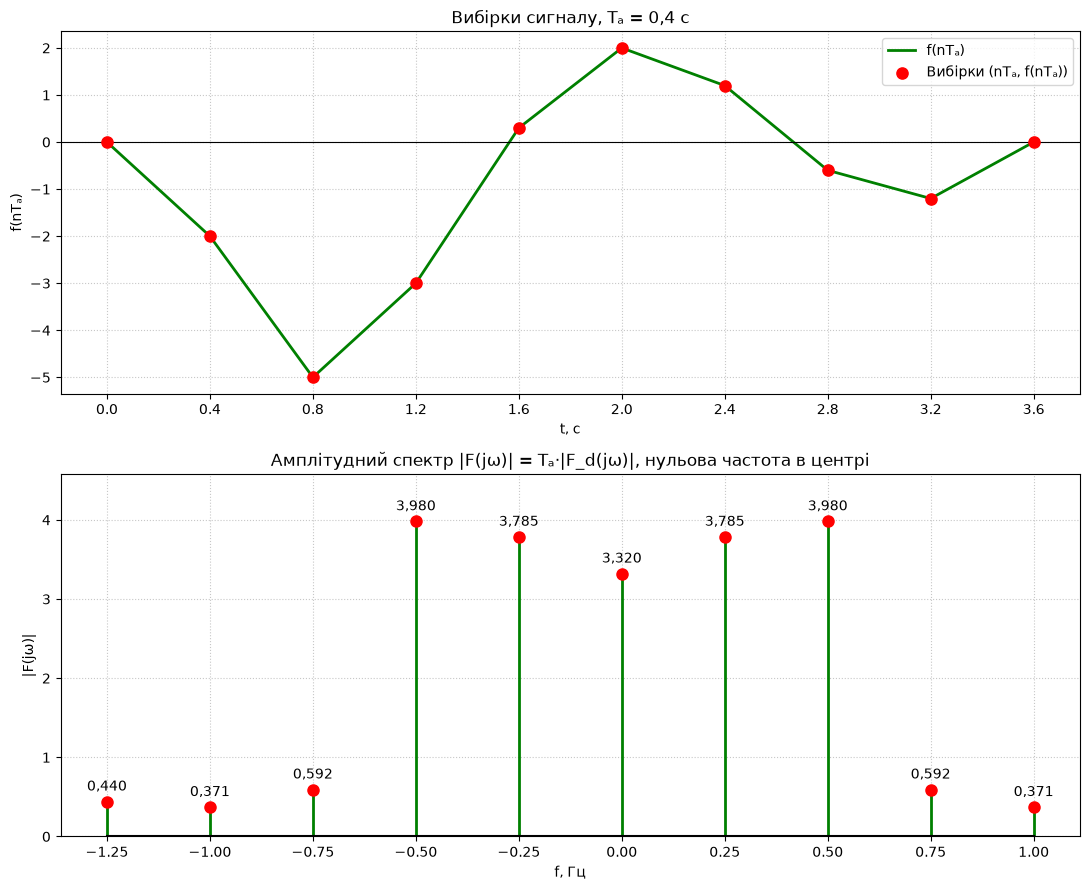

In [6]:
Path("figures").mkdir(exist_ok=True)
figure, (signal_axis, spectrum_axis) = plt.subplots(2, 1, figsize=(11, 9))

signal_axis.plot(sample_times, sample_values, color="green", linewidth=2, label="f(nTₐ)")
signal_axis.scatter(sample_times, sample_values, color="red", s=65, zorder=5, label="Вибірки (nTₐ, f(nTₐ))")
signal_axis.axhline(0, color="black", linewidth=0.8)
signal_axis.set_title("Вибірки сигналу, Tₐ = 0,4 с")
signal_axis.set_xlabel("t, с")
signal_axis.set_ylabel("f(nTₐ)")
signal_axis.set_xticks(sample_times)
signal_axis.grid(linestyle=":", alpha=0.7)
signal_axis.legend()

markers, stems, baseline = spectrum_axis.stem(centred_frequencies, centred_amplitude_spectrum,
                                               linefmt="green", markerfmt="o", basefmt="black")
plt.setp(stems, linewidth=2)
plt.setp(markers, color="red", markersize=8, zorder=5)
for frequency, amplitude in zip(centred_frequencies, centred_amplitude_spectrum):
    spectrum_axis.annotate(f"{amplitude:.3f}".replace(".", ","), (frequency, amplitude),
                           textcoords="offset points", xytext=(0, 8), ha="center")
spectrum_axis.set_title("Амплітудний спектр |F(jω)| = Tₐ·|F_d(jω)|, нульова частота в центрі")
spectrum_axis.set_xlabel("f, Гц")
spectrum_axis.set_ylabel("|F(jω)|")
spectrum_axis.set_xticks(centred_frequencies)
spectrum_axis.set_ylim(0, 1.15 * np.max(centred_amplitude_spectrum))
spectrum_axis.grid(linestyle=":", alpha=0.7)

plt.tight_layout()
plt.savefig("figures/dft_spectrum.png", dpi=180)
plt.show()

## Підсумок

Основні параметри, максимум спектра і найбільша різниця між ручним розрахунком та бібліотекою.

In [7]:
print(f"Variant {variant_number}: N = {sample_count}, Ta = {sampling_period} s,"
      f" fa = {sampling_frequency} Hz, delta f = {frequency_resolution} Hz")
print(f"F_d(0) = {clean(hand_spectrum[0].real):.6f}, maximum |F(jw_k)| = {amplitude_spectrum[maximum_index]:.6f}"
      f" at f = +-{line_frequencies[maximum_index]:.2f} Hz")
print(f"hand DFT vs np.fft.fft: max difference {spectrum_difference:.1e}")
print(f"inverse DFT error {hand_restore_error:.1e}, Parseval {signal_energy:.6f} = {spectrum_energy:.6f}")

Variant 23: N = 10, Ta = 0.4 s, fa = 2.5 Hz, delta f = 0.25 Hz
F_d(0) = -8.300000, maximum |F(jw_k)| = 3.980386 at f = +-0.50 Hz
hand DFT vs np.fft.fft: max difference 1.3e-14
inverse DFT error 4.3e-15, Parseval 45.330000 = 45.330000
